<div style="height: 50px; background: linear-gradient(to right, #e9d5ff, #a855f7, #6b21a8);"></div>

# Visualisation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

from sklearn import metrics

import warnings
warnings.filterwarnings('ignore')

In [8]:
df = pd.read_excel("cardio_data_ml.xlsx", parse_dates=['date'])
display(df.head())

,date,country,id,active,age_group,alco,ap_hi,ap_lo,cholesterol,gender,gluc,height,occupation,smoke,weight,pca,disease
0,2021-05-03,Indonesia,0,1,5,0,110,80,1,2,1,168,Architect,0,62.0,0.9108,0
1,2021-08-05,Malaysia,1,1,5,0,140,90,3,1,1,156,Accountant,0,85.0,0.9380,1
2,2022-11-13,Indonesia,2,0,5,0,130,70,3,1,1,165,Chef,0,64.0,0.9190,1
3,2018-10-31,Singapore,3,1,4,0,150,100,1,2,1,169,Lawyer,0,82.0,0.7938,1
4,2020-09-25,Singapore,4,0,4,0,100,60,1,1,1,156,Architect,0,56.0,0.7346,0


In [9]:
df['height'] = df['height'].astype(float)

In [10]:
# overall information and data types of the columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         70000 non-null  datetime64[us]
 1   country      70000 non-null  str           
 2   id           70000 non-null  int64         
 3   active       70000 non-null  int64         
 4   age_group    70000 non-null  int64         
 5   alco         70000 non-null  int64         
 6   ap_hi        70000 non-null  int64         
 7   ap_lo        70000 non-null  int64         
 8   cholesterol  70000 non-null  int64         
 9   gender       70000 non-null  int64         
 10  gluc         70000 non-null  int64         
 11  height       70000 non-null  float64       
 12  occupation   70000 non-null  str           
 13  smoke        70000 non-null  int64         
 14  weight       70000 non-null  float64       
 15  pca          70000 non-null  float64       
 16  disease      70

In [11]:
df.describe()

,date,id,active,age_group,alco,ap_hi,ap_lo,cholesterol,gender,gluc,height,smoke,weight,pca,disease
count,70000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,2020-07-01 10:51:11.314285,49972.419900,0.803729,4.855057,0.053771,126.848314,82.964514,1.366871,1.349571,1.226457,164.359229,0.088129,74.205690,0.905270,0.499700
min,2018-01-01 00:00:00,0.000000,0.000000,2.000000,0.000000,60.000000,40.000000,1.000000,1.000000,1.000000,55.000000,0.000000,10.000000,0.420800,0.000000
25%,2019-04-04 00:00:00,25006.750000,1.000000,4.000000,0.000000,120.000000,80.000000,1.000000,1.000000,1.000000,159.000000,0.000000,65.000000,0.780800,0.000000
50%,2020-06-30 00:00:00,50001.500000,1.000000,5.000000,0.000000,120.000000,80.000000,1.000000,1.000000,1.000000,165.000000,0.000000,72.000000,0.917800,0.000000
75%,2021-09-30 00:00:00,74889.250000,1.000000,5.000000,0.000000,140.000000,90.000000,2.000000,2.000000,1.000000,170.000000,0.000000,82.000000,0.951400,1.000000
max,2023-01-01 00:00:00,99999.000000,1.000000,6.000000,1.000000,200.000000,200.000000,3.000000,2.000000,3.000000,250.000000,1.000000,200.000000,1.257700,1.000000
std,NaN,28851.302323,0.397179,0.740231,0.225568,17.430948,16.824860,0.680250,0.476838,0.572270,8.210126,0.283484,14.395757,0.121503,0.500003


<div style="height: 50px; background: linear-gradient(to right, lightblue, blue, darkblue);"></div>

#### Correlation Matrix

In [12]:
# Select numerical columns only
numerical_data = df.select_dtypes(include=np.number)

# Compute the correlation matrix
numerical_data.corr()

,id,active,age_group,alco,ap_hi,ap_lo,cholesterol,gender,gluc,height,smoke,weight,pca,disease
id,1.000000,0.003755,0.006160,0.001210,0.002014,0.000455,0.006106,0.003502,0.002467,-0.003038,-0.003699,-0.001830,0.006296,0.003799
active,0.003755,1.000000,-0.011728,0.025476,0.002377,0.006323,0.009911,0.005866,-0.006770,-0.006570,0.025858,-0.016867,-0.007223,-0.035653
age_group,0.006160,-0.011728,1.000000,-0.031266,0.179229,0.090920,0.137124,-0.022675,0.087097,-0.075119,-0.045330,0.042324,0.978303,0.212366
alco,0.001210,0.025476,-0.031266,1.000000,0.032286,0.030557,0.035760,0.170966,0.011246,0.094419,0.340094,0.067113,0.102380,-0.007330
ap_hi,0.002014,0.002377,0.179229,0.032286,1.000000,0.529529,0.192330,0.060029,0.090760,0.015983,0.027846,0.264669,0.320279,0.419442
ap_lo,0.000455,0.006323,0.090920,0.030557,0.529529,1.000000,0.115153,0.050232,0.051688,0.019978,0.021994,0.185042,0.227304,0.256312
cholesterol,0.006106,0.009911,0.137124,0.035760,0.192330,0.115153,1.000000,-0.035821,0.451578,-0.050226,0.010354,0.141768,0.166073,0.221147
gender,0.003502,0.005866,-0.022675,0.170966,0.060029,0.050232,-0.035821,1.000000,-0.020491,0.499033,0.338135,0.155406,0.010900,0.008109
gluc,0.002467,-0.006770,0.087097,0.011246,0.090760,0.051688,0.451578,-0.020491,1.000000,-0.018595,-0.004756,0.106857,0.099566,0.089307
height,-0.003038,-0.006570,-0.075119,0.094419,0.015983,0.019978,-0.050226,0.499033,-0.018595,1.000000,0.187989,0.290968,-0.056304,-0.010821


### Pairplot
**Pairplot Analysis** is a graphical way to see visually whether there is any relationship between the numerical columns.

We need not input the numerical columns. It automatically detects all the numerical columns and plots the pairplot for each pair of columns.

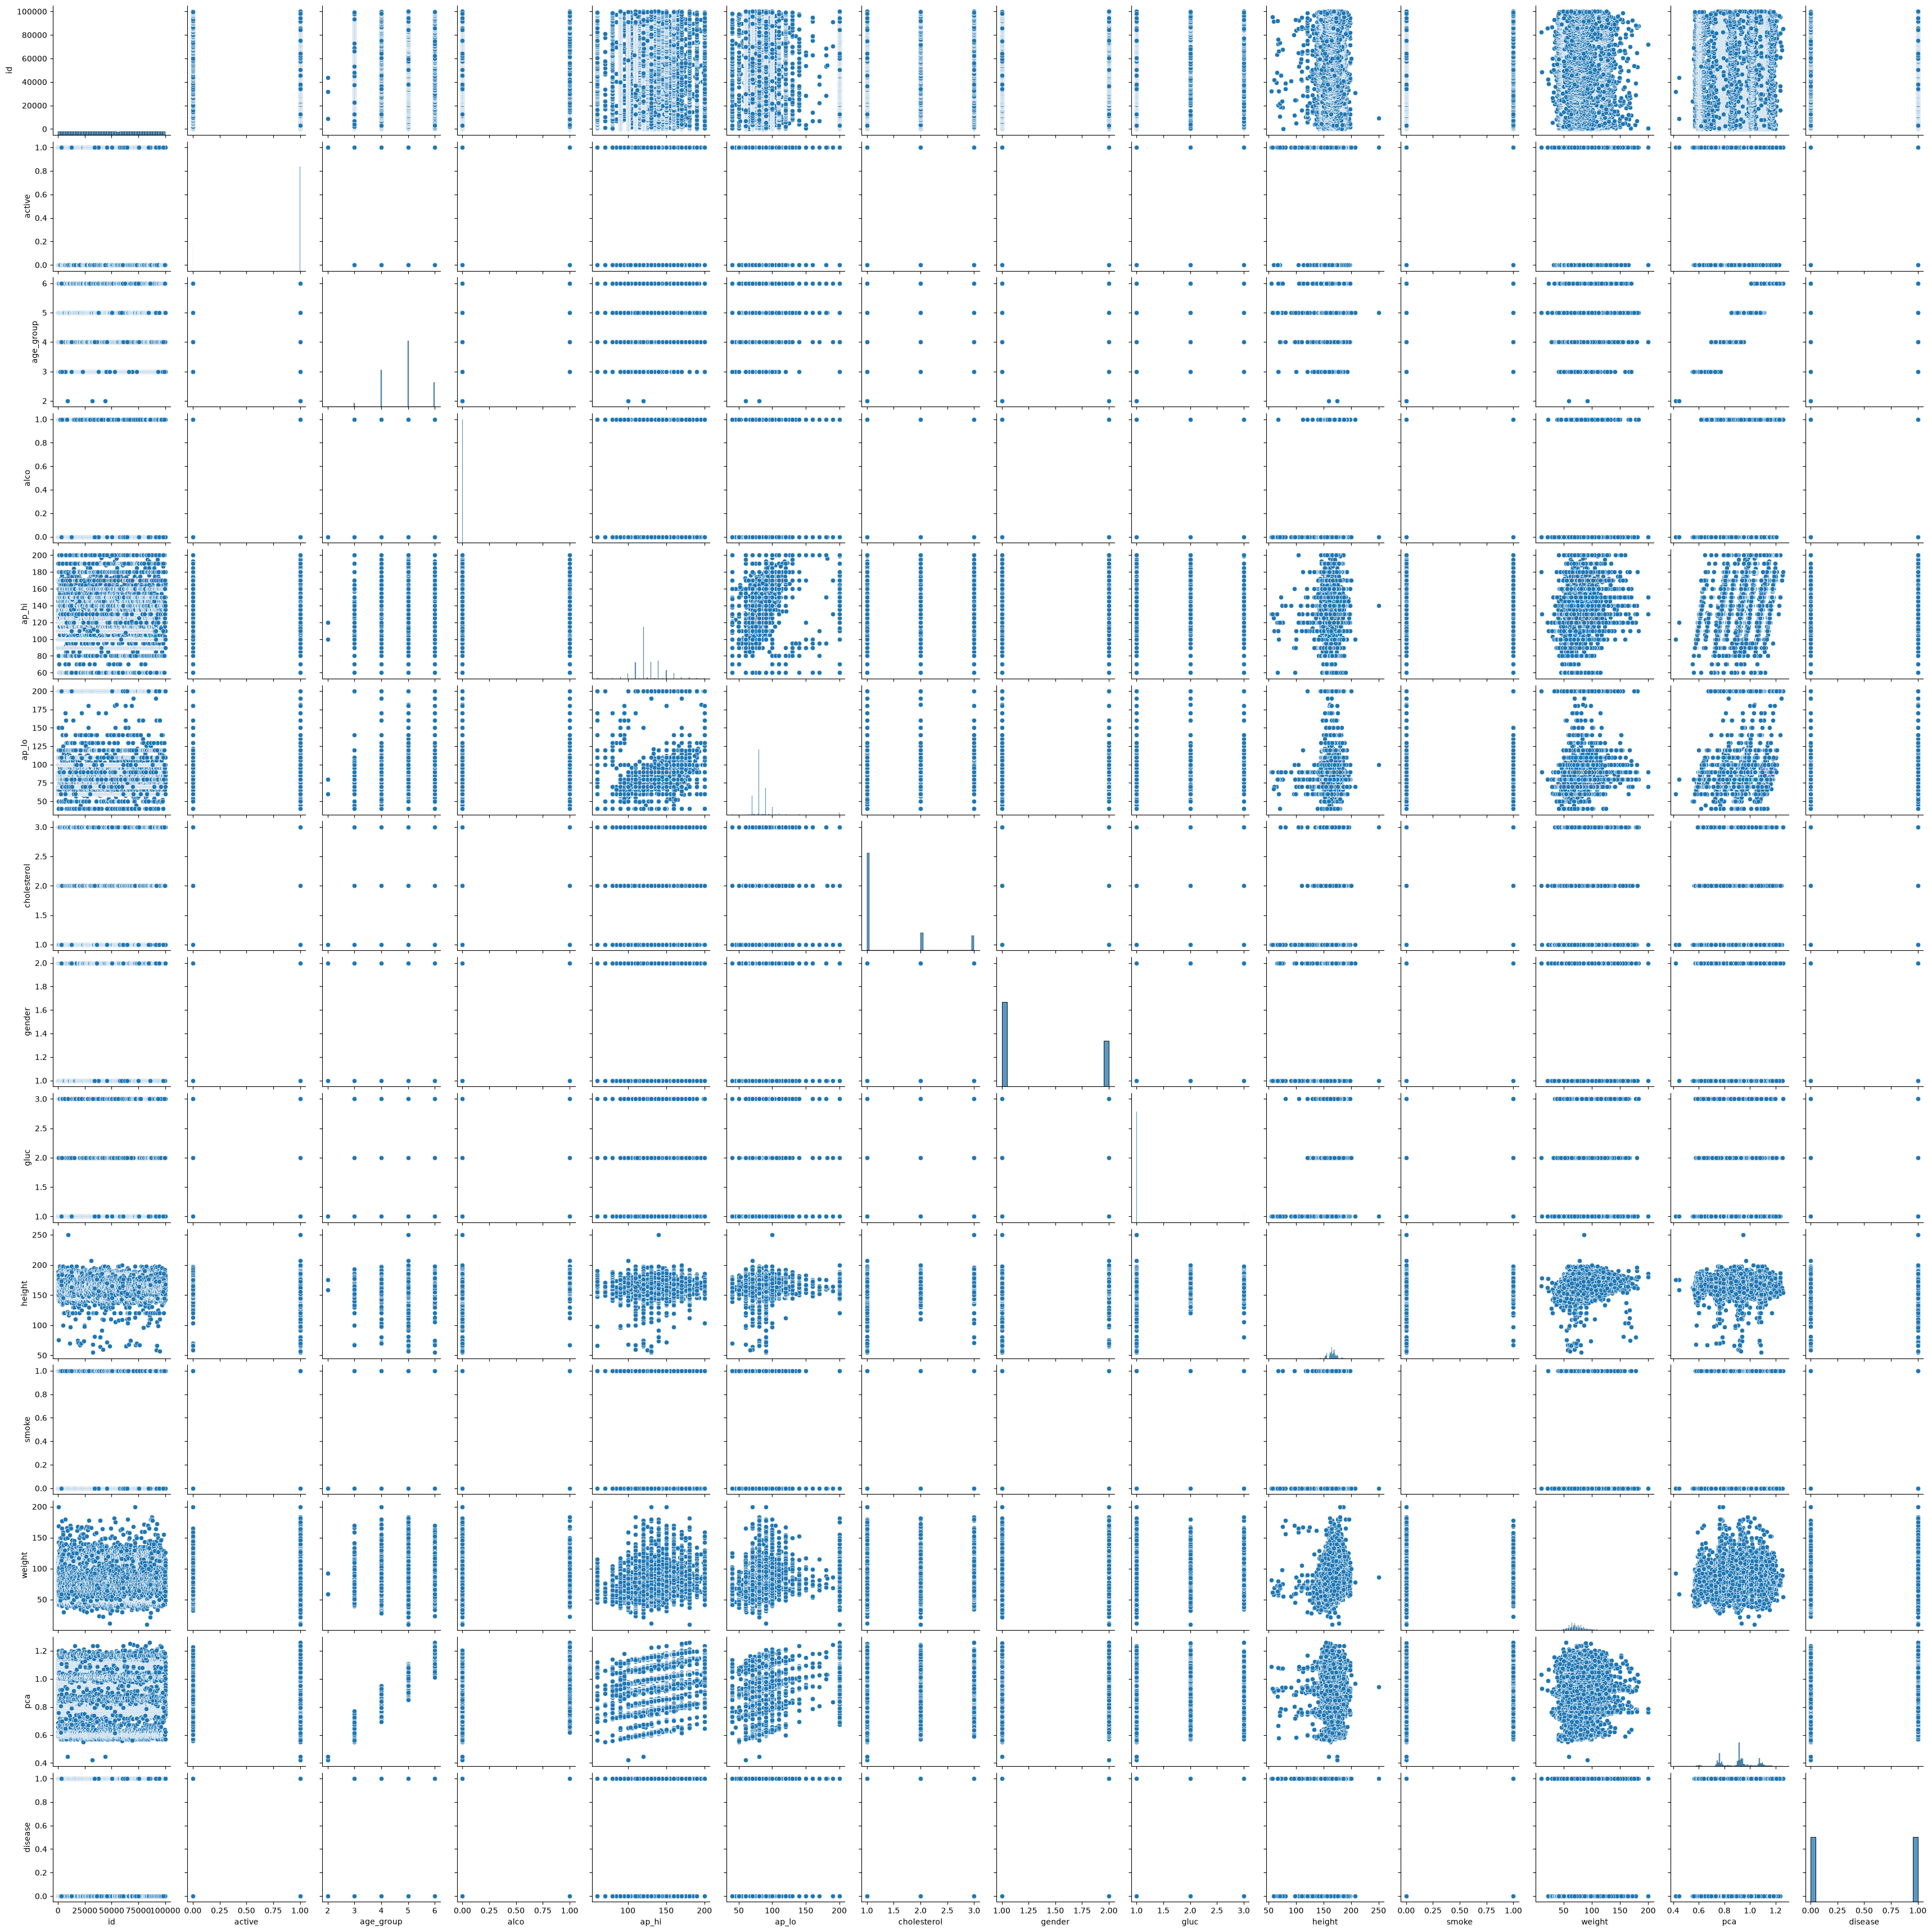

In [13]:
# Pairplot analysis
sns.pairplot(numerical_data)
plt.show()

<img src="https://d138zd1ktt9iqe.cloudfront.net/media/seo_landing_files/diksha-q-how-to-calculate-correlation-coefficient-01-1609233340.png" width="600"  height="200">

#### Column/ Bar chartessing missing, inaccurate, misleading information, data imputation methods

## Correlation Heatmaps.

,id,active,age_group,alco,ap_hi,ap_lo,cholesterol,gender,gluc,height,smoke,weight,pca,disease
id,1.000000,0.003755,0.006160,0.001210,0.002014,0.000455,0.006106,0.003502,0.002467,-0.003038,-0.003699,-0.001830,0.006296,0.003799
active,0.003755,1.000000,-0.011728,0.025476,0.002377,0.006323,0.009911,0.005866,-0.006770,-0.006570,0.025858,-0.016867,-0.007223,-0.035653
age_group,0.006160,-0.011728,1.000000,-0.031266,0.179229,0.090920,0.137124,-0.022675,0.087097,-0.075119,-0.045330,0.042324,0.978303,0.212366
alco,0.001210,0.025476,-0.031266,1.000000,0.032286,0.030557,0.035760,0.170966,0.011246,0.094419,0.340094,0.067113,0.102380,-0.007330
ap_hi,0.002014,0.002377,0.179229,0.032286,1.000000,0.529529,0.192330,0.060029,0.090760,0.015983,0.027846,0.264669,0.320279,0.419442
ap_lo,0.000455,0.006323,0.090920,0.030557,0.529529,1.000000,0.115153,0.050232,0.051688,0.019978,0.021994,0.185042,0.227304,0.256312
cholesterol,0.006106,0.009911,0.137124,0.035760,0.192330,0.115153,1.000000,-0.035821,0.451578,-0.050226,0.010354,0.141768,0.166073,0.221147
gender,0.003502,0.005866,-0.022675,0.170966,0.060029,0.050232,-0.035821,1.000000,-0.020491,0.499033,0.338135,0.155406,0.010900,0.008109
gluc,0.002467,-0.006770,0.087097,0.011246,0.090760,0.051688,0.451578,-0.020491,1.000000,-0.018595,-0.004756,0.106857,0.099566,0.089307
height,-0.003038,-0.006570,-0.075119,0.094419,0.015983,0.019978,-0.050226,0.499033,-0.018595,1.000000,0.187989,0.290968,-0.056304,-0.010821


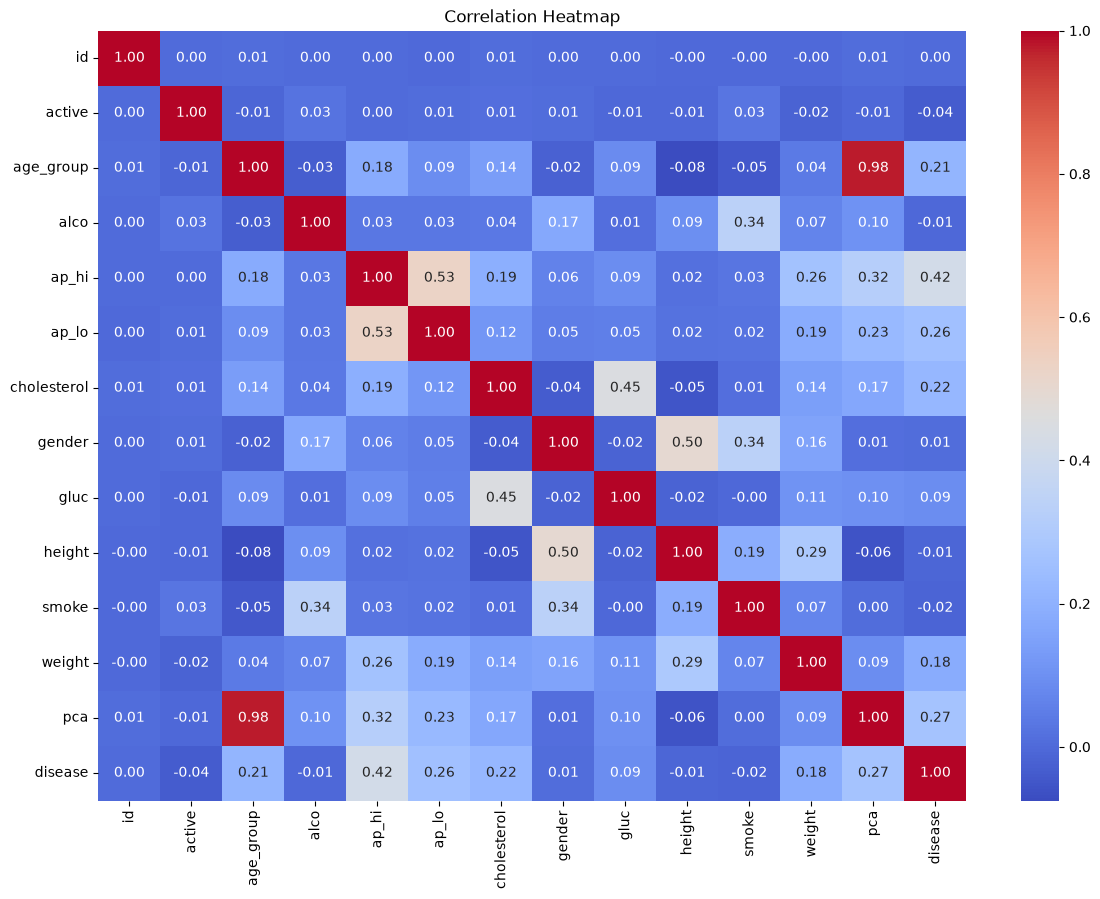

In [25]:
# Compute the correlation matrix
corr_matrix = df.corr(numeric_only=True)
display(corr_matrix)

# Create a heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()


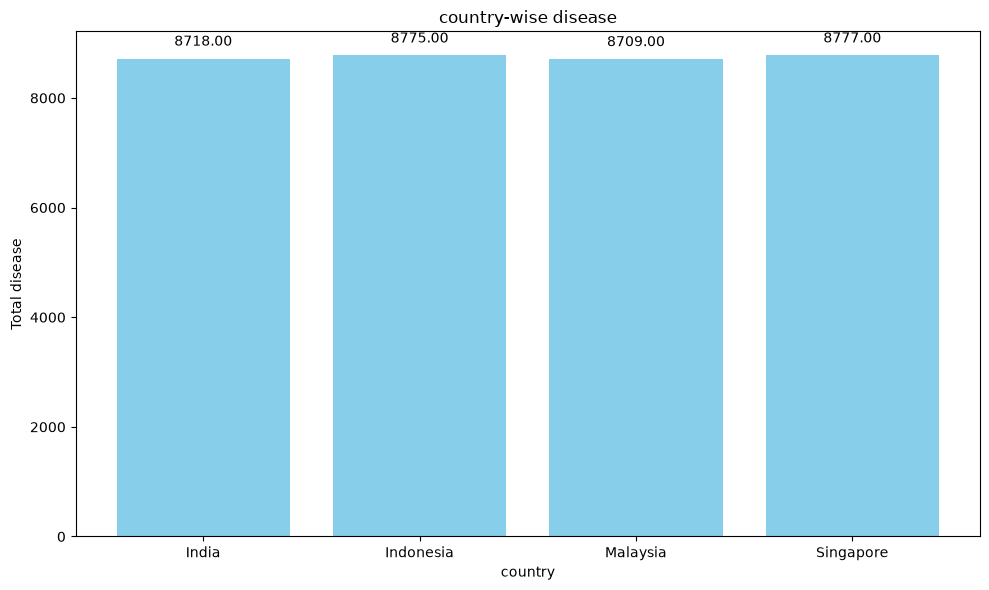

In [14]:
# Group by 'Segment' and sum up 'Sales'
segment_data = df.groupby('country')['disease'].sum().reset_index()

# Plotting Segment-wise Sales
plt.figure(figsize=(10, 6))
plt.bar(segment_data['country'], segment_data['disease'], color='skyblue')

# Adding title and labels
plt.title('country-wise disease')
plt.xlabel('country')
plt.ylabel('Total disease')

# Adding value labels on top of the bars for better readability
for i, value in enumerate(segment_data['disease']):
    plt.text(i, value + 0.02 * max(segment_data['disease']), 
             f'{value:.2f}', ha='center', va='bottom')

# Display the plot
plt.tight_layout()
plt.show()

In [15]:
display(df)

,date,country,id,active,age_group,alco,ap_hi,ap_lo,cholesterol,gender,gluc,height,occupation,smoke,weight,pca,disease
0,2021-05-03,Indonesia,0,1,5,0,110,80,1,2,1,168.0,Architect,0,62.0,0.9108,0
1,2021-08-05,Malaysia,1,1,5,0,140,90,3,1,1,156.0,Accountant,0,85.0,0.9380,1
2,2022-11-13,Indonesia,2,0,5,0,130,70,3,1,1,165.0,Chef,0,64.0,0.9190,1
3,2018-10-31,Singapore,3,1,4,0,150,100,1,2,1,169.0,Lawyer,0,82.0,0.7938,1
4,2020-09-25,Singapore,4,0,4,0,100,60,1,1,1,156.0,Architect,0,56.0,0.7346,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,2020-11-17,India,64340,1,4,0,200,200,1,1,2,152.0,Chef,0,85.0,0.8888,1
69996,2020-05-09,Malaysia,84604,1,5,0,200,200,1,2,1,176.0,Others,0,100.0,1.0458,1
69997,2022-10-26,India,91461,1,5,0,200,200,1,2,1,173.0,Engineer,1,85.0,1.0459,1
69998,2020-02-15,India,94377,1,5,0,200,200,1,2,1,173.0,Others,0,112.0,1.0458,1


Text(0, 0.5, 'Total disease')

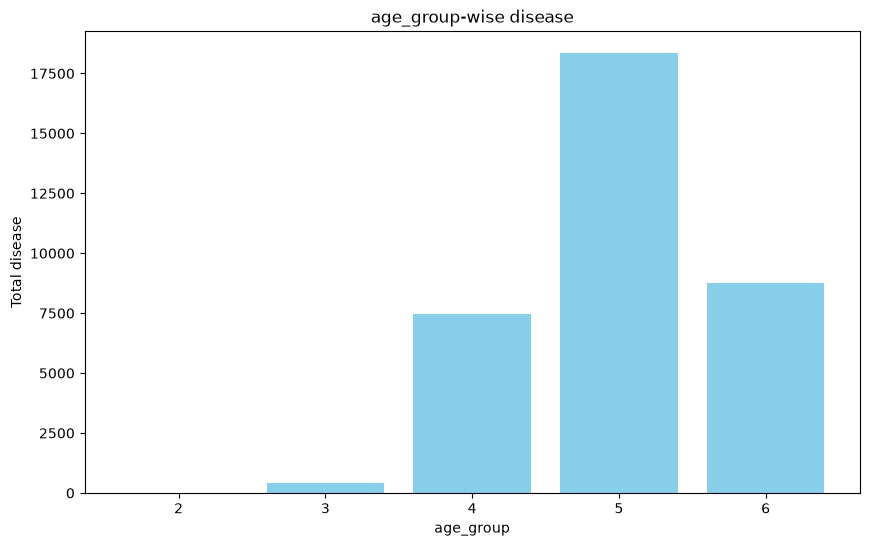

In [16]:
# Group by 'age_group' and sum up 'disease'
segment_data = df.groupby('age_group')['disease'].sum().reset_index()

# Plotting Segment-wise Sales
plt.figure(figsize=(10, 6))
plt.bar(segment_data['age_group'], segment_data['disease'], color='skyblue')

# Adding title and labels
plt.title('age_group-wise disease')
plt.xlabel('age_group')
plt.ylabel('Total disease')

([<matplotlib.axis.XTick at 0x17909d507d0>,
 [Text(0, 0, '0'), Text(1, 0, '1')])

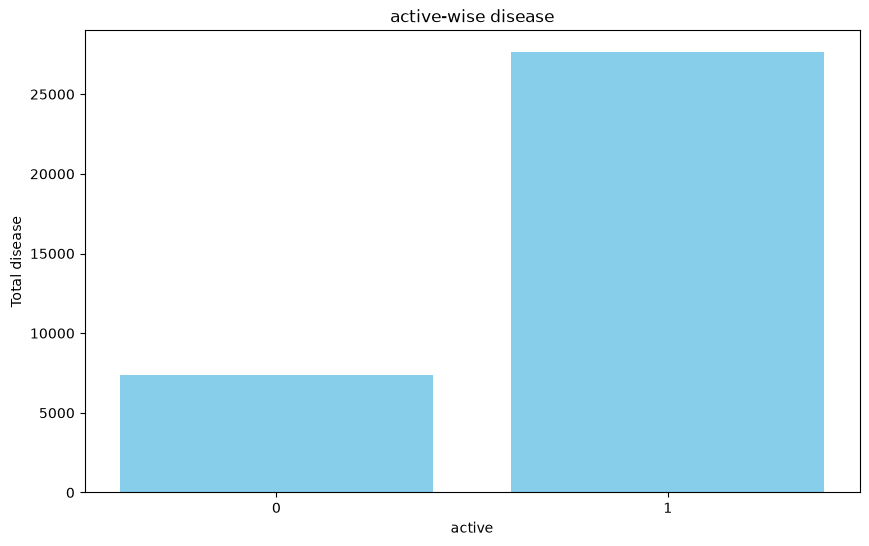

In [17]:
# Group by 'active' and sum up 'disease'
segment_data = df.groupby('active')['disease'].sum().reset_index()

# Plotting Segment-wise Sales
plt.figure(figsize=(10, 6))
plt.bar(segment_data['active'], segment_data['disease'], color='skyblue')

# Adding title and labels
plt.title('active-wise disease')
plt.xlabel('active')
plt.ylabel('Total disease')
plt.xticks([0, 1])

([<matplotlib.axis.XTick at 0x17909da0910>,
 [Text(1, 0, '1'), Text(2, 0, '2')])

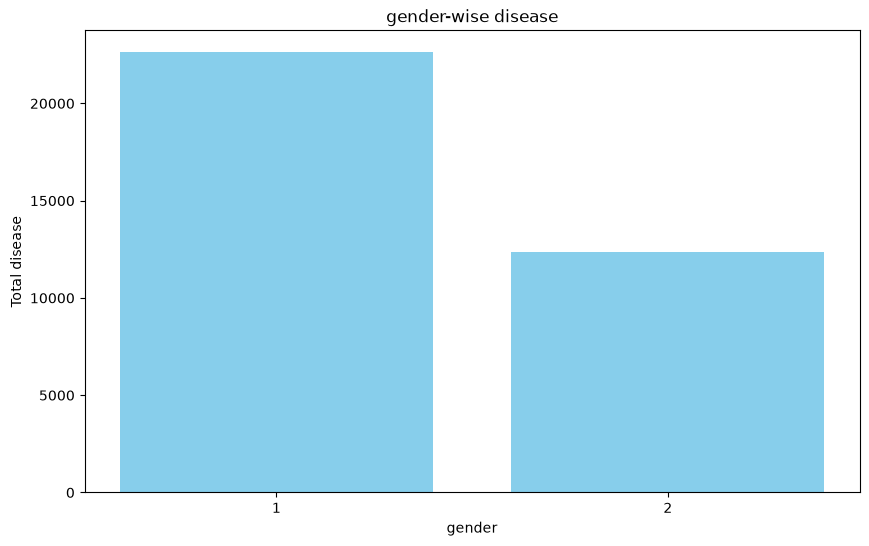

In [18]:
# Group by 'gender' and sum up 'disease'
segment_data = df.groupby('gender')['disease'].sum().reset_index()

# Plotting Segment-wise Sales
plt.figure(figsize=(10, 6))
plt.bar(segment_data['gender'], segment_data['disease'], color='skyblue')

# Adding title and labels
plt.title('gender-wise disease')
plt.xlabel('gender')
plt.ylabel('Total disease')
plt.xticks([1, 2])

Text(0, 0.5, 'Total disease')

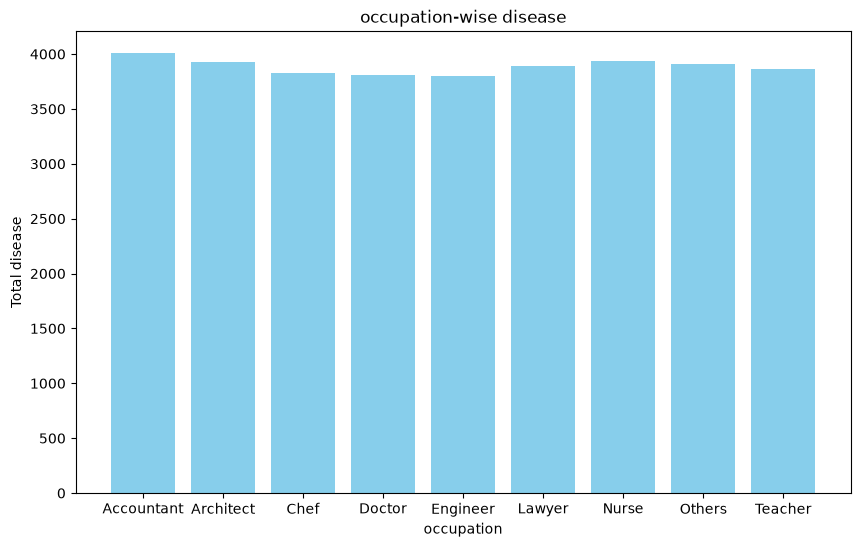

In [19]:
# Group by 'occupation' and sum up 'disease'
segment_data = df.groupby('occupation')['disease'].sum().reset_index()

# Plotting Segment-wise Sales
plt.figure(figsize=(10, 6))
plt.bar(segment_data['occupation'], segment_data['disease'], color='skyblue')

# Adding title and labels
plt.title('occupation-wise disease')
plt.xlabel('occupation')
plt.ylabel('Total disease')

([<matplotlib.axis.XTick at 0x17909fc5e50>,
 [Text(0, 0, '0'), Text(1, 0, '1')])

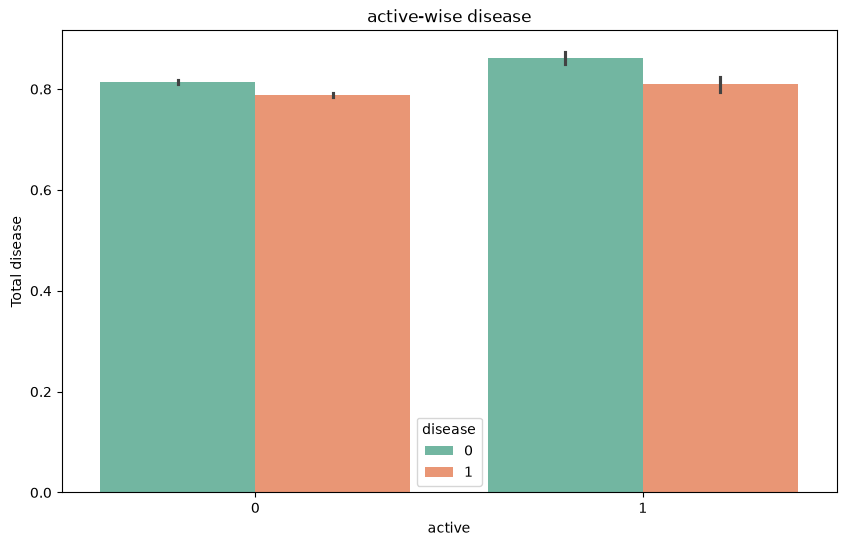

In [22]:
# Group by 'smoke' and sum up 'disease'
segment_data = df.groupby(['smoke', 'active'])['disease'].count().reset_index()
#segment_data = df.groupby('disease')['disease'].count()

# Plotting Segment-wise Sales
plt.figure(figsize=(10, 6))
#plt.bar(segment_data['smoke'], segment_data['disease'], color='skyblue')

sns.barplot(
    data=df,
    x='smoke',
    y='active',
    hue='disease',
    palette='Set2',
    legend=True
)
# Adding title and labels
plt.title('active-wise disease')
plt.xlabel('active')
plt.ylabel('Total disease')
plt.xticks([0, 1])

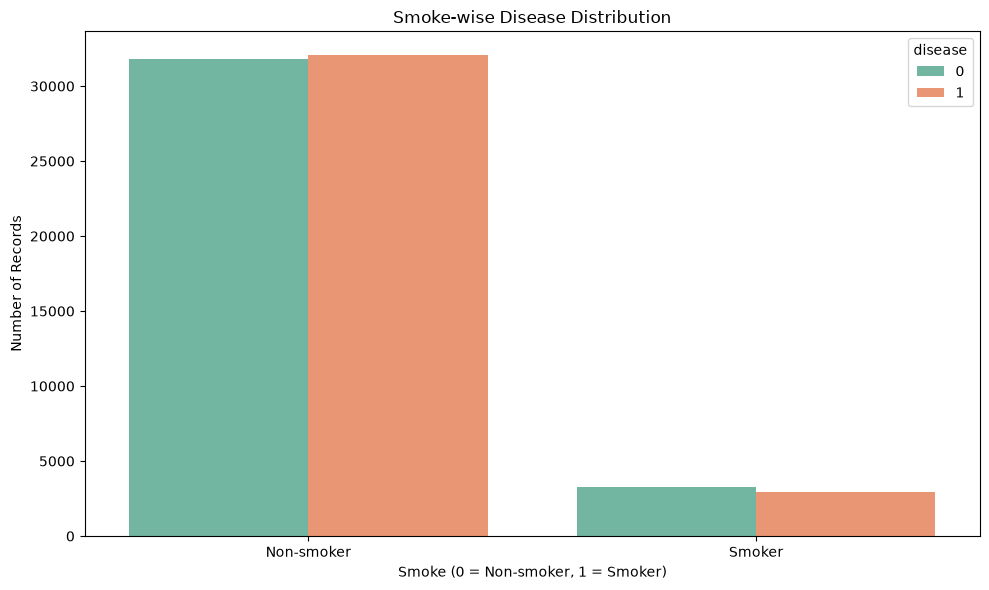

In [21]:
segment_data = df.groupby(['smoke', 'disease']).size().reset_index(name='count')

# Create bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_data,
    x='smoke',
    y='count',
    hue='disease',
    palette='Set2',
    legend=True
)

# Add title and labels
plt.title('Smoke-wise Disease Distribution')
plt.xlabel('Smoke (0 = Non-smoker, 1 = Smoker)')
plt.ylabel('Number of Records')
plt.xticks([0, 1], ['Non-smoker', 'Smoker'])
#plt.legend(title='Disease', labels=['No Disease (0)', 'Disease (1)'])

plt.tight_layout()
plt.show()

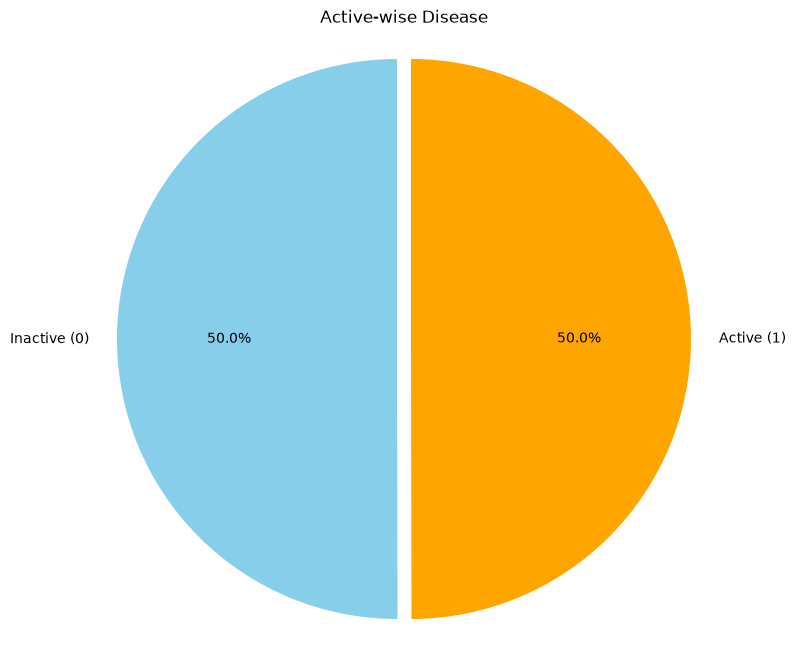

In [23]:
import matplotlib.pyplot as plt

# Group by 'active' and sum up 'disease'
segment_data = df.groupby('disease')['disease'].count()

# Create pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    segment_data,
    labels=['Inactive (0)', 'Active (1)'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['skyblue', 'orange'],
    explode=(0, 0.05)
)

# Add title
plt.title('Active-wise Disease')

# Keep pie chart circular
plt.axis('equal')

plt.show()

<div style="height: 50px; background: linear-gradient(to right, #e9d5ff, #a855f7, #6b21a8);"></div>
